<a href="https://colab.research.google.com/github/ThomasAko/physics-constraints-qm7-qm9/blob/main/QM7_DeepChem_Diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# QM7 via DeepChem: diagnosing a broken data pipeline

**Thomas Ako**

This notebook is the first version of a study asking whether a physics term in a neural network's loss helps it learn. Molecules from QM7, loaded with DeepChem's `load_qm7`, are classified as high or low atomization energy from their Coulomb matrices, and a virial-theorem penalty (2⟨T⟩ + ⟨V⟩ = 0) is added on two auxiliary output heads.

**What happened.** Every model, from random forests to tuned networks, stalled near 60% accuracy, and the virial penalty gave no measurable gain. Three checks then examined the result:

* **Check A** (five seeds): no detectable effect of the penalty.
* **Check B**: the penalty can be satisfied exactly by the output heads alone, without any physics.
* **Check C**, a composition-only baseline, exposed the real problem. Atom counts explained only 19% of the variance in the labels, a quantity they should almost fully determine, so DeepChem's features and labels do not match (Section 1.7).

I keep this notebook as a record of how the problem was found. The corrected study loads the original `qm7.mat`, where the same models reach 97% accuracy, and continues to QM9: [Physics_Constraints_QM7_to_QM9.ipynb](Physics_Constraints_QM7_to_QM9.ipynb).

Runtime: about 30–40 minutes on CPU.

In [1]:
!pip install -q deepchem rdkit keras-tuner

In [ ]:
import os, json, time, random, math, inspect
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

import tensorflow as tf
# Let TensorFlow share the GPU with PyTorch (Part 2) instead of reserving all of its memory
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
from tensorflow.keras import layers, models

import deepchem as dc
import deepchem.feat as feat
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); random.seed(SEED)

/usr/local/lib/python3.13/dist-packages/deepchem/feat/smiles_tokenizer.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.



# Part 1: QM7, classifying atomization energy from Coulomb matrices

## 1.1 Data

QM7 contains 7,165 small organic molecules (up to 23 atoms) with DFT atomization energies. Each molecule is represented by its **Coulomb matrix**:

$$C_{ij} = \begin{cases} 0.5\,Z_i^{2.4} & i = j \\ \dfrac{Z_i Z_j}{\lvert R_i - R_j \rvert} & i \neq j \end{cases}$$

The diagonal encodes each atom's identity, and the off-diagonal entries the nuclear repulsion between atom pairs. Each 23 × 23 matrix is flattened into 529 features and standardized, so the large diagonal values do not drown out the interaction terms.

Two facts about the data as DeepChem delivers it, both checked in the next cell:

* **Molecules are dropped.** DeepChem parses QM7's structure file with RDKit, which rejects a few hundred molecules containing charged nitrogen or five-bonded carbon written without a formal charge. 6,838 molecules remain.
* **The split is random**, not by scaffold (`load_qm7` defaults to `splitter='random'`), so the test set contains the same chemical families as the training set. That makes the task easier, which matters when judging the ~60% accuracies below.

In [ ]:
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")        # silence per-molecule RDKit valence warnings; the dropped count is reported below

featurizer_obj = feat.CoulombMatrix(max_atoms=23)
SPLITTER = "random"                    # DeepChem's default for QM7; "scaffold" would test unseen chemical families
with np.errstate(divide="ignore"):     # zero distances on the diagonal are overwritten by 0.5 Z^2.4
    tasks, datasets, transformers = dc.molnet.load_qm7(featurizer=featurizer_obj, splitter=SPLITTER)
train_dataset, valid_dataset, test_dataset = datasets

n_used = sum(len(d) for d in datasets)
print(f"splitter: {SPLITTER} | molecules used: {n_used} of 7,165 ({7165 - n_used} dropped by RDKit)")
print("transformers applied to y:", [type(t).__name__ for t in transformers])

splitter: random | molecules used: 6838 of 7,165 (327 dropped by RDKit)
transformers applied to y: ['NormalizationTransformer']


In [ ]:
def flat(ds): return ds.X.reshape(ds.X.shape[0], -1)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(flat(train_dataset))   # fit on training data only
X_val_scaled   = scaler.transform(flat(valid_dataset))
X_test_scaled  = scaler.transform(flat(test_dataset))

y_train_raw, y_val_raw, y_test_raw = train_dataset.y, valid_dataset.y, test_dataset.y

**Target.** A molecule is labelled *High_Energy* if its atomization energy is above the **training-set** median, otherwise *Low_Energy*. Using the training median only keeps test information out of the labels.

In [ ]:
median_energy = np.median(y_train_raw)
encoder = OneHotEncoder(sparse_output=False).fit(np.array([["High_Energy"], ["Low_Energy"]]))

def one_hot(y):
    return encoder.transform(np.where(y > median_energy, "High_Energy", "Low_Energy").reshape(-1, 1))

y_train, y_val, y_test = one_hot(y_train_raw), one_hot(y_val_raw), one_hot(y_test_raw)
y_true = np.argmax(y_test, axis=1)          # column 0 = High_Energy
for name, a in [("train", X_train_scaled), ("valid", X_val_scaled), ("test", X_test_scaled)]:
    print(f"{name:6s} {a.shape}")

train  (5470, 529)
valid  (684, 529)
test   (684, 529)


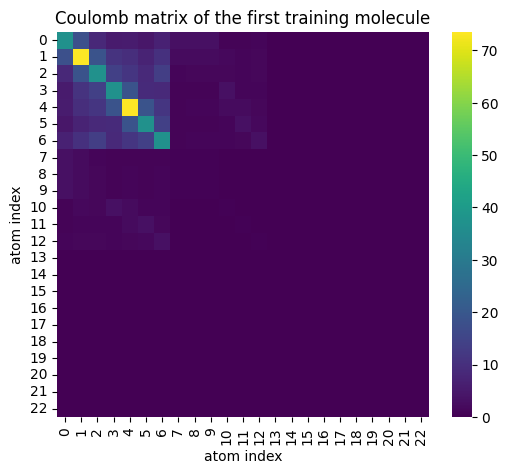

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(train_dataset.X[0].reshape(23, 23), cmap="viridis")
plt.title("Coulomb matrix of the first training molecule"); plt.xlabel("atom index"); plt.ylabel("atom index")
plt.show()

## 1.2 Data-only baselines

Before adding any physics, we need to know how well the same models do on the data alone. Three models set that reference.

1. **Random forest (100 trees):** a non-parametric reference that needs no gradient training, so it shows whether a neural network earns its extra complexity. Its size grows with the data: a fully grown tree on $n = 5{,}470$ training molecules has at most $2n - 1 = 10{,}939$ nodes, so 100 trees hold at most about 1.09 million.
2. **Funnel network:** 529 → 256 → 128 → 64 → 32 → 2, dropout 0.2 after the first three hidden layers. It compresses the Coulomb matrix step by step into a few features that separate the two classes.
3. **Tuned network:** 529 → 64 → 416 → 224 → 256 → 128 → 2, dropout only after the 256-unit layer, found by a Keras-Tuner Hyperband search over depth, width and dropout placement. Hyperband trains many candidates briefly and gives the promising ones more epochs; the search ran 412 trials in about two hours (≈ 17 s per trial). The 64-unit first layer is a bottleneck that forces a compact summary of the input.

### Parameter counts

A dense layer from $n_\text{in}$ to $n_\text{out}$ units has $n_\text{in} \times n_\text{out}$ weights plus $n_\text{out}$ biases; dropout and softmax add none.

| Funnel layer | Weights | Biases | Parameters |
|---|---|---|---|
| 529 → 256 | 529 × 256 = 135,424 | 256 | 135,680 |
| 256 → 128 | 256 × 128 = 32,768 | 128 | 32,896 |
| 128 → 64 | 128 × 64 = 8,192 | 64 | 8,256 |
| 64 → 32 | 64 × 32 = 2,048 | 32 | 2,080 |
| 32 → 2 | 32 × 2 = 64 | 2 | 66 |
| **Total** | | | **178,978** |

| Tuned layer | Weights | Biases | Parameters |
|---|---|---|---|
| 529 → 64 | 529 × 64 = 33,856 | 64 | 33,920 |
| 64 → 416 | 64 × 416 = 26,624 | 416 | 27,040 |
| 416 → 224 | 416 × 224 = 93,184 | 224 | 93,408 |
| 224 → 256 | 224 × 256 = 57,344 | 256 | 57,600 |
| 256 → 128 | 256 × 128 = 32,768 | 128 | 32,896 |
| 128 → 2 | 128 × 2 = 256 | 2 | 258 |
| **Total** | | | **245,122** |

76% of the funnel's parameters (135,680 of 178,978) sit in its first layer. The diamond's bottleneck shrinks that layer to 33,920 and moves most of its capacity into the 416 → 224 layer.

### How precisely can 684 test molecules rank these models?

Each test molecule is classified either correctly or not, so the measured accuracy $\hat p$ is a binomial proportion with standard error $\text{SE} = \sqrt{\hat p(1-\hat p)/n}$. For $\hat p \approx 0.60$ and $n = 684$:

$$\text{SE} = \sqrt{0.60 \times 0.40 / 684} = \sqrt{0.000351} = 0.0187 \approx 1.9 \text{ percentage points}, \qquad 1.96 \times \text{SE} \approx 3.7 \text{ percentage points}$$

So an accuracy of 0.60 means roughly 0.56–0.64 at 95% confidence. For the *difference* between two independent accuracies the SE grows by $\sqrt 2$ to about 2.65 points, so a gap of about 5.2 points is needed at 95%. Both models are scored on the same molecules, so a paired test (McNemar's) is sharper, but either way gaps of a few points are within noise. This is why Check A (Section 1.4) compares models over several seeds.

### What the search tells us

Repeated searches returned different architectures with similar scores, so the choice between them falls within validation noise. Picking the best of 412 trials on one 684-molecule validation set also favours architectures that happen to fit that set's noise, which biases the winner's score upward. On a problem this small, random search with 20–50 trials (Bergstra & Bengio, 2012) or a sensible fixed architecture is usually enough.

The search result is hard-coded below, so the notebook runs without it. Set `RUN_TUNER = True` to repeat the search.

In [ ]:
RUN_TUNER = False
HP_TUNED = {"num_layers": 5,
            "units_0": 64,  "dropout_0": False, "units_1": 416, "dropout_1": False,
            "units_2": 224, "dropout_2": False, "units_3": 256, "dropout_3": True,
            "units_4": 128, "dropout_4": False}
HP_FUNNEL = {"num_layers": 4,
             "units_0": 256, "dropout_0": True, "units_1": 128, "dropout_1": True,
             "units_2": 64,  "dropout_2": True, "units_3": 32,  "dropout_3": False}

if RUN_TUNER:
    import keras_tuner as kt
    def model_builder_general(hp):
        m = tf.keras.Sequential([tf.keras.layers.Input(shape=(529,))])
        for i in range(hp.Int("num_layers", 1, 8)):
            m.add(tf.keras.layers.Dense(hp.Int(f"units_{i}", 32, 512, step=32), activation="relu"))
            if hp.Boolean(f"dropout_{i}"): m.add(tf.keras.layers.Dropout(0.2))
        m.add(tf.keras.layers.Dense(2, activation="softmax"))
        m.compile("adam", "categorical_crossentropy", metrics=["accuracy"])
        return m
    tuner = kt.Hyperband(model_builder_general, objective="val_accuracy", max_epochs=100, factor=2,
                         hyperband_iterations=10, directory="tuner", project_name="qm7_layers")
    tuner.search(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val))
    best = tuner.get_best_hyperparameters(1)[0]
    HP_TUNED = {k: best.get(k) for k in best.values}

In [ ]:
def dense_net(hp):
    m = models.Sequential([layers.Input(shape=(529,))])
    for i in range(hp["num_layers"]):
        m.add(layers.Dense(hp[f"units_{i}"], activation="relu"))
        if hp[f"dropout_{i}"]: m.add(layers.Dropout(0.2))
    m.add(layers.Dense(2, activation="softmax"))
    m.compile("adam", "categorical_crossentropy", metrics=["accuracy"])
    return m

def scores(y_pred):
    return dict(Accuracy=accuracy_score(y_true, y_pred),
                **{"Precision (High)": precision_score(y_true, y_pred, pos_label=0),
                   "Recall (High)": recall_score(y_true, y_pred, pos_label=0),
                   "F1": f1_score(y_true, y_pred, pos_label=0)})

EPOCHS = 100
results = {}

rf_model = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_train_scaled, np.argmax(y_train, 1))
results["Random forest"] = scores(rf_model.predict(X_test_scaled))

# Both networks validate on DeepChem's validation set (the original notebook used a random 20%
# split for the funnel network; this makes the comparison like-for-like)
model_tuned = dense_net(HP_TUNED)
hist_tuned = model_tuned.fit(X_train_scaled, y_train, epochs=EPOCHS, batch_size=32,
                             validation_data=(X_val_scaled, y_val), verbose=0)
results["NN, tuned"] = scores(np.argmax(model_tuned.predict(X_test_scaled, verbose=0), 1))

model_funnel = dense_net(HP_FUNNEL)
hist_funnel = model_funnel.fit(X_train_scaled, y_train, epochs=EPOCHS, batch_size=32,
                               validation_data=(X_val_scaled, y_val), verbose=0)
results["NN, funnel"] = scores(np.argmax(model_funnel.predict(X_test_scaled, verbose=0), 1))

pd.DataFrame(results).T.round(4)

,Accuracy,Precision (High),Recall (High),F1
Random forest,0.6316,0.6293,0.5640,0.5949
"NN, tuned",0.6053,0.5868,0.5976,0.5921
"NN, funnel",0.6213,0.6088,0.5884,0.5984


In [ ]:
from sklearn.metrics import confusion_matrix

preds = {
    "Random forest": rf_model.predict(X_test_scaled),
    "NN, tuned": np.argmax(model_tuned.predict(X_test_scaled, verbose=0), 1),
    "NN, funnel": np.argmax(model_funnel.predict(X_test_scaled, verbose=0), 1),
}

rows = []
for name, y_pred in preds.items():
    # labels=[1, 0] puts low (1) first and high (0) second, so .ravel() gives tn, fp, fn, tp with high as positive
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[1, 0]).ravel()
    rows.append({"Model": name, "TP": tp, "FN": fn, "FP": fp, "TN": tn, "Predicted high": tp + fp})

pd.DataFrame(rows).set_index("Model")

,TP,FN,FP,TN,Predicted high
Model,,,,,
Random forest,185,143,109,247,294
"NN, tuned",196,132,138,218,334
"NN, funnel",193,135,124,232,317


*All* three baselines land at 60–63% accuracy, and their F1 scores on the high-energy class are nearly identical (0.592–0.598). They differ mainly in where they draw the decision boundary. The random forest predicts "high" only 294 times for 328 truly high molecules, which gives it the best precision (0.629) and the worst recall (0.564). The tuned network predicts "high" 334 times, which gives it the best recall (0.598) and the most false positives. The largest accuracy gap, 2.6 points, is well within the roughly 5-point margin needed for significance on 684 molecules. The two-hour architecture search therefore produced no measurable gain over the simple funnel network.

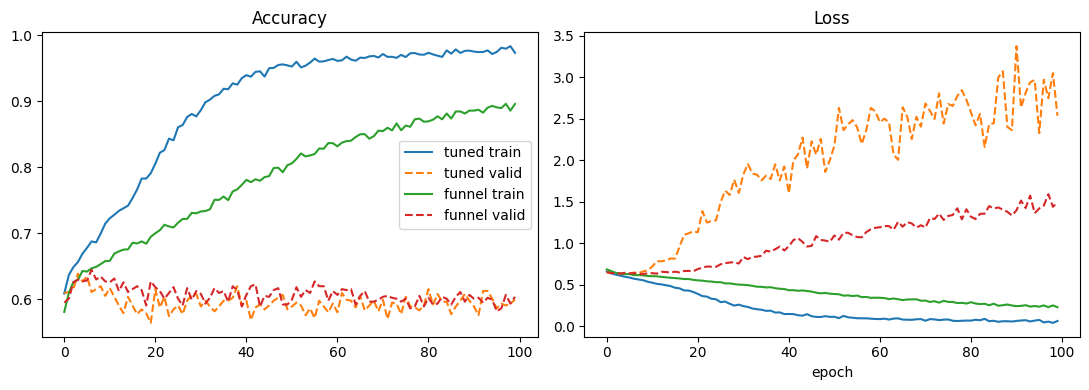

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for h, name in [(hist_tuned, "tuned"), (hist_funnel, "funnel")]:
    ax[0].plot(h.history["accuracy"], label=f"{name} train"); ax[0].plot(h.history["val_accuracy"], "--", label=f"{name} valid")
    ax[1].plot(h.history["loss"], label=f"{name} train");     ax[1].plot(h.history["val_loss"], "--", label=f"{name} valid")
ax[0].set_title("Accuracy"); ax[1].set_title("Loss"); ax[0].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()


**Both networks overfit early.** Validation accuracy peaks at about 0.62–0.63 within five epochs and then levels off near 0.60, while training accuracy keeps rising, to about 0.97 (tuned) and 0.89 (funnel). Validation loss starts at ln 2 ≈ 0.69, the value for random guessing, and then climbs while validation accuracy stays flat: the networks grow more confident without becoming more correct. The tuned network, with more parameters and only one dropout layer, overfits sooner and further.

Because both architectures stall at the same accuracy, the limit looks like a property of the data or the representation rather than the network, which is what Check C tests. It also sets the bar for the virial term in Section 1.3: a network that overfits this much will gain from any regularizer, so a small improvement from the physics term would not by itself show that the physics helps.

## 1.3 Adding physics: a virial-theorem penalty

For a molecule at equilibrium, the virial theorem links the expectation values of kinetic and potential energy:

$$2\langle T\rangle + \langle V\rangle = 0$$

I added two scalar output heads, one for ⟨T⟩ and one for ⟨V⟩, on top of each network's last hidden layer, and penalized violations of the theorem:

$$\mathcal{L} = \mathcal{L}_\text{cross-entropy} + \lambda_\text{phys}\,\overline{(2T + V)^2}$$

The physics weight is λ = 0.1 and the networks train for 100 epochs.

In [ ]:
class CoulombPINN(tf.keras.Model):
    def __init__(self, hp, lambda_phys=0.1):
        super().__init__()
        self.hidden_layers = []
        for i in range(hp["num_layers"]):
            self.hidden_layers.append(layers.Dense(hp[f"units_{i}"], activation="relu"))
            if hp[f"dropout_{i}"]: self.hidden_layers.append(layers.Dropout(0.2))
        self.class_out = layers.Dense(2, activation="softmax")
        self.T_head = layers.Dense(1)          # predicted kinetic energy  <T>
        self.V_head = layers.Dense(1)          # predicted potential energy <V>
        self.lambda_phys = lambda_phys

    def hidden_features(self, x, training=False):
        for l in self.hidden_layers:
            x = l(x, training=training) if isinstance(l, layers.Dropout) else l(x)
        return x

    def call(self, x, training=False):
        h = self.hidden_features(x, training)
        return self.class_out(h), self.T_head(h), self.V_head(h)

    def loss_terms(self, x, y, training):
        p, T, V = self(x, training=training)
        data_loss = tf.reduce_mean(tf.keras.losses.categorical_crossentropy(y, p))
        physics_loss = tf.reduce_mean(tf.square(2.0 * T + V))
        return p, data_loss, physics_loss

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            p, dl, pl = self.loss_terms(x, y, True)
            loss = dl + self.lambda_phys * pl
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_variables), self.trainable_variables))
        self.compiled_metrics.update_state(y, p)
        return {**{m.name: m.result() for m in self.metrics}, "loss": loss, "data_loss": dl, "physics_loss": pl}

    def test_step(self, data):
        x, y = data
        p, dl, pl = self.loss_terms(x, y, False)
        self.compiled_metrics.update_state(y, p)
        return {**{m.name: m.result() for m in self.metrics}, "loss": dl + self.lambda_phys * pl,
                "data_loss": dl, "physics_loss": pl}

LAMBDA_PHYS, PINN_EPOCHS = 0.1, 100
pinn = {}
for name, hp in [("tuned", HP_TUNED), ("funnel", HP_FUNNEL)]:
    m = CoulombPINN(hp, LAMBDA_PHYS); m.compile(optimizer="adam", metrics=["accuracy"])
    m.fit(X_train_scaled, y_train, epochs=PINN_EPOCHS, batch_size=32,
          validation_data=(X_val_scaled, y_val), verbose=0)
    pinn[name] = m
    results[f"Virial NN, {name}"] = scores(np.argmax(m.predict(X_test_scaled, verbose=0)[0], 1))

pd.DataFrame(results).T.round(4)

/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:670: UserWarning: `model.compiled_metrics()` is deprecated. Instead, use e.g.:
```
for metric in self.metrics:
    metric.update_state(y, y_pred)
```

  return self._compiled_metrics_update_state(
/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:670: UserWarning: `model.compiled_metrics()` is deprecated. Instead, use e.g.:
```
for metric in self.metrics:
    metric.update_state(y, y_pred)
```

  return self._compiled_metrics_update_state(


,Accuracy,Precision (High),Recall (High),F1
Random forest,0.6316,0.6293,0.5640,0.5949
"NN, tuned",0.6053,0.5868,0.5976,0.5921
"NN, funnel",0.6213,0.6088,0.5884,0.5984
"Virial NN, tuned",0.5892,0.5706,0.5793,0.5749
"Virial NN, funnel",0.6140,0.6013,0.5793,0.5901


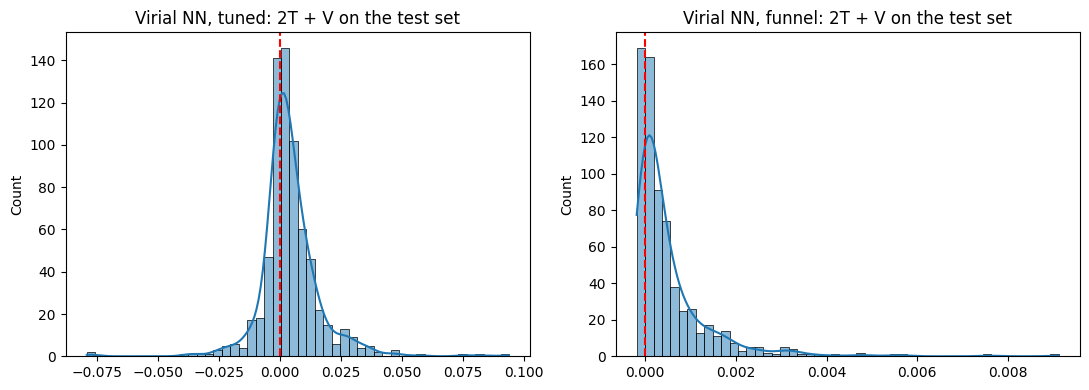

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, m) in zip(axes, pinn.items()):
    _, T, V = m.predict(X_test_scaled, verbose=0)
    sns.histplot((2*T + V).ravel(), bins=50, kde=True, ax=ax)
    ax.axvline(0, color="r", ls="--"); ax.set_title(f"Virial NN, {name}: 2T + V on the test set")
plt.tight_layout(); plt.show()

**First reading.** With matched training data and epochs, the penalty gives no gain: the virial networks score 58.9% (tuned) and 61.4% (funnel), against 60.5% and 62.1% for the plain networks. The virial residuals, however, cluster tightly around zero, which looks like the constraint is being met. The three checks below ask whether any effect survives across seeds, whether the constraint actually requires physics, and whether the baseline itself is sound.

## 1.4 Check A: is the gain larger than run-to-run noise?

One training run per model can't separate a real effect from luck. Here the funnel network is trained with and without the penalty over several seeds, with the same number of epochs for both.




/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:670: UserWarning: `model.compiled_metrics()` is deprecated. Instead, use e.g.:
```
for metric in self.metrics:
    metric.update_state(y, y_pred)
```

  return self._compiled_metrics_update_state(
/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:670: UserWarning: `model.compiled_metrics()` is deprecated. Instead, use e.g.:
```
for metric in self.metrics:
    metric.update_state(y, y_pred)
```

  return self._compiled_metrics_update_state(
/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:670: UserWarning: `model.compiled_metrics()` is deprecated. Instead, use e.g.:
```
for metric in self.metrics:
    metric.update_state(y, y_pred)
```

  return self._compiled_metrics_update_state(
/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:670: UserWarning: `model.compiled_metrics()` is deprecated. Instead, use e.g.:
```
for me

,mean,std,min,max
model,,,,
"NN, funnel",0.5994,0.0106,0.5863,0.6126
"Virial NN, funnel",0.6050,0.0182,0.5833,0.6316


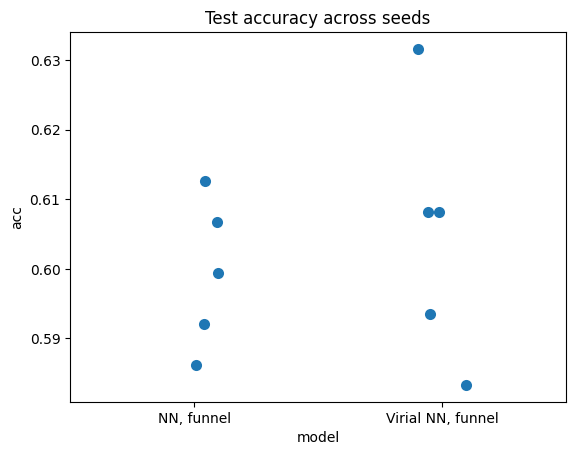

In [ ]:
RUN_SEED_STUDY = True
SEED_LIST, SEED_EPOCHS = [0, 1, 2, 3, 4], 100
seed_rows = []
if RUN_SEED_STUDY:
    for s in SEED_LIST:
        tf.keras.utils.set_random_seed(s)
        m = dense_net(HP_FUNNEL)
        m.fit(X_train_scaled, y_train, epochs=SEED_EPOCHS, batch_size=32, validation_data=(X_val_scaled, y_val), verbose=0)
        seed_rows.append(dict(seed=s, model="NN, funnel", acc=accuracy_score(y_true, np.argmax(m.predict(X_test_scaled, verbose=0), 1))))
        tf.keras.utils.set_random_seed(s)
        m = CoulombPINN(HP_FUNNEL, LAMBDA_PHYS); m.compile(optimizer="adam", metrics=["accuracy"])
        m.fit(X_train_scaled, y_train, epochs=SEED_EPOCHS, batch_size=32, validation_data=(X_val_scaled, y_val), verbose=0)
        seed_rows.append(dict(seed=s, model="Virial NN, funnel", acc=accuracy_score(y_true, np.argmax(m.predict(X_test_scaled, verbose=0)[0], 1))))
    seed_df = pd.DataFrame(seed_rows)
    display(seed_df.groupby("model").acc.agg(["mean", "std", "min", "max"]).round(4))
    sns.stripplot(data=seed_df, x="model", y="acc", size=8); plt.title("Test accuracy across seeds"); plt.show()

In [ ]:
from scipy.stats import ttest_ind
a = seed_df.loc[seed_df.model == "Virial NN, funnel", "acc"]
b = seed_df.loc[seed_df.model == "NN, funnel", "acc"]
print(ttest_ind(a, b, equal_var=False))

TtestResult(statistic=np.float64(0.588881941005055), pvalue=np.float64(0.5759815467537692), df=np.float64(6.44663526675303))


**Check A result: no detectable effect.** Over five seeds, the virial network averages 60.5% against 59.9% for the plain funnel, a difference of +0.6 points. The standard error of that difference is about 0.9 points (Welch's t ≈ 0.6, p ≈ 0.6), and the 95% interval runs from about −1.7 to +2.8 points. Seed-to-seed variation (standard deviation 1.1–1.8 points) is about as large as the test-set sampling noise from Section 1.2, so a single run can show a gain or a loss by chance; the virial seeds alone span 58.3% to 63.2%. The penalty also makes training less stable, with a spread 1.7 times wider than the plain network's. Any real effect is at most a few points, too small to measure with this data.

## 1.5 Check B: does the penalty actually constrain the network?

Both heads read the same hidden vector **h**:

$$T = \mathbf w_T\!\cdot\!\mathbf h + b_T,\qquad V = \mathbf w_V\!\cdot\!\mathbf h + b_V \;\;\Rightarrow\;\; 2T+V = (2\mathbf w_T + \mathbf w_V)\cdot\mathbf h + (2b_T + b_V)$$

QM7 has no labels for ⟨T⟩ or ⟨V⟩, so nothing ties them to real values. The residual can therefore be driven to zero without any physics, for example by setting $\mathbf w_V = -2\mathbf w_T$ and $b_V = -2b_T$, which makes it vanish **for every molecule whatever h contains**. The hidden layers can also take part, by keeping **h** small along the direction $2\mathbf w_T + \mathbf w_V$.

The cell below runs two tests:

1. **Constructive test:** keep the trained network exactly as it is, including the ⟨T⟩ head, and replace only the ⟨V⟩ head with $\mathbf w_V = -2\mathbf w_T,\ b_V = -2b_T$. If the residual becomes zero for every test molecule while ⟨T⟩ still varies and the class predictions are unchanged, the constraint can be met without the network learning anything about the molecules.
2. **Gradient share:** how strongly the physics term pushed on the shared hidden layers, compared with the classification loss.

In [ ]:
def physics_gradient_share(m, n=512):
    xb, yb = tf.constant(X_train_scaled[:n], tf.float32), tf.constant(y_train[:n], tf.float32)
    hidden = [v for l in m.hidden_layers for v in l.trainable_variables]
    with tf.GradientTape(persistent=True) as tape:
        _, dl, pl = m.loss_terms(xb, yb, False)
        weighted_pl = m.lambda_phys * pl          # computed inside the tape so it can be differentiated
    g_data = tf.linalg.global_norm(tape.gradient(dl, hidden)).numpy()
    g_phys = tf.linalg.global_norm(tape.gradient(weighted_pl, hidden)).numpy()
    return g_data, g_phys

for name, m in pinn.items():
    X = tf.constant(X_test_scaled, tf.float32)
    p, T, V = [t.numpy() for t in m(X)]
    H = m.hidden_features(X).numpy()
    wT, bT = m.T_head.kernel.numpy(), m.T_head.bias.numpy()
    V_constructed = H @ (-2 * wT) + (-2 * bT)             # V head replaced by -2 x T head
    g_data, g_phys = physics_gradient_share(m)
    print(f"Virial NN, {name}")
    print(f"  as trained:              RMS(2T + V) = {np.sqrt(np.mean((2*T + V)**2)):.2e}   spread of T = {T.std():.3f}")
    print(f"  with V head := -2 T head: RMS(2T + V) = {np.sqrt(np.mean((2*T + V_constructed)**2)):.2e}   "
          f"spread of T = {T.std():.3f}   (classifier untouched)")
    print(f"  gradient into hidden layers: data {g_data:.2e}, physics {g_phys:.2e} (physics/data = {g_phys/g_data:.1e})\n")

Virial NN, tuned
  as trained:              RMS(2T + V) = 1.33e-02   spread of T = 1.409
  with V head := -2 T head: RMS(2T + V) = 1.86e-07   spread of T = 1.409   (classifier untouched)
  gradient into hidden layers: data 6.70e-01, physics 2.87e-04 (physics/data = 4.3e-04)

Virial NN, funnel
  as trained:              RMS(2T + V) = 1.03e-03   spread of T = 0.765
  with V head := -2 T head: RMS(2T + V) = 1.33e-07   spread of T = 0.765   (classifier untouched)
  gradient into hidden layers: data 2.23e-01, physics 1.19e-06 (physics/data = 5.3e-06)



**Reading Check B.** The constructed ⟨V⟩ head gives a residual at floating-point zero for every molecule, while ⟨T⟩ keeps varying and the classifier is untouched. The virial penalty can therefore be met perfectly by the output layer alone, so the small residuals in Section 1.3 are **not** evidence of physical consistency.

During training the network may still have used its hidden layers to shrink the residual; the gradient-share numbers show how hard the term pushed on them. But what it pushed them towards is keeping $(2\mathbf w_T + \mathbf w_V)\cdot\mathbf h$ constant, a geometric property of the representation, not a physical one. Without labels for ⟨T⟩ or ⟨V⟩, the term can only act as a regulariser.



## 1.6 Check C: is ~60% a sensible baseline?

Atomization energy grows strongly with molecular size, so even a crude description of composition should separate high from low energy fairly well. The atomic numbers can be recovered exactly from the Coulomb-matrix diagonal ($Z = (2C_{ii})^{1/2.4}$), so this cell trains classifiers on **atom counts alone**: number of H, C, N, O, S and total atoms. If this beats the Coulomb-matrix models by a wide margin, the problem lies in the representation or the split, not in the choice of model.

In [ ]:
def atom_counts(ds):
    C = ds.X.reshape(len(ds.X), 23, 23)
    Z = np.rint((2 * np.clip(np.diagonal(C, axis1=1, axis2=2), 0, None)) ** (1/2.4)).astype(int)
    feats = {f"n_{s}": (Z == z).sum(1) for s, z in [("H", 1), ("C", 6), ("N", 7), ("O", 8), ("S", 16)]}
    feats["n_atoms"] = (Z > 0).sum(1)
    return pd.DataFrame(feats)

A_train, A_test = atom_counts(train_dataset), atom_counts(test_dataset)
print(A_train.describe().loc[["mean", "min", "max"]].round(2))

for name, clf in [("Logistic regression on atom counts", LogisticRegression(max_iter=2000)),
                  ("Random forest on atom counts", RandomForestClassifier(200, random_state=SEED))]:
    clf.fit(A_train, np.argmax(y_train, 1))
    results[name] = scores(clf.predict(A_test))

pd.DataFrame(results).T.round(4)

        n_H   n_C  n_N   n_O   n_S  n_atoms
mean   8.74  5.01  0.9  0.84  0.03    15.52
min    0.00  0.00  0.0  0.00  0.00     1.00
max   15.00  7.00  3.0  3.00  1.00    22.00


,Accuracy,Precision (High),Recall (High),F1
Random forest,0.6316,0.6293,0.5640,0.5949
"NN, tuned",0.6053,0.5868,0.5976,0.5921
"NN, funnel",0.6213,0.6088,0.5884,0.5984
"Virial NN, tuned",0.5892,0.5706,0.5793,0.5749
"Virial NN, funnel",0.6140,0.6013,0.5793,0.5901
Logistic regression on atom counts,0.6316,0.6776,0.4421,0.5351
Random forest on atom counts,0.6550,0.6402,0.6402,0.6402


In [ ]:
from sklearn.linear_model import LinearRegression

y_cont = train_dataset.y.ravel()
print("corr(n_atoms, energy):", round(np.corrcoef(A_train.n_atoms, y_cont)[0, 1], 3))
print("R² of linear model on counts:", round(LinearRegression().fit(A_train, y_cont).score(A_train, y_cont), 3))
print(A_train[A_train.n_atoms < 5])

corr(n_atoms, energy): -0.267
R² of linear model on counts: 0.189
      n_H  n_C  n_N  n_O  n_S  n_atoms
323     2    0    0    0    0        2
1613    2    0    0    0    0        2
2741    2    0    0    0    0        2
3507    1    0    0    0    0        1


**Reading the diagnostic.** Atomization energy grows with molecule size, so the correlation with atom count should be strongly negative and a linear model on atom counts should explain nearly all of the variance. Instead, the correlation is only −0.27 and the linear model explains 19%. Four training "molecules" contain only one or two hydrogen atoms and no heavy atom, which is impossible in QM7. The labels and features from DeepChem's loader do not match, so the problem lies in the data, not the models.

## 1.7 What Check C revealed: the data, not the models

Five atom counts do at least as well as the 529-feature Coulomb matrix: a random forest on counts reaches 65.5% accuracy, the best in the table, and a logistic regression on counts ties the Coulomb random forest at 63.2%. The real warning is the absolute level. Atomization energy is close to *extensive*, roughly a sum of contributions from each atom and bond, so composition alone should predict it well and a median split should be easy. Instead every model, even a linear one on atom counts, stalls near 60%.

A direct test of the labels, compared with the original QM7 file, confirms the problem:

| Diagnostic | Original QM7 file | DeepChem data |
|---|---|---|
| Correlation of molecule size with energy | −0.971 | −0.267 |
| R² of a linear model on atom counts | 0.992 | 0.189 |
| Smallest molecule | 4 atoms, at least one carbon | 1–2 hydrogen atoms only |

On DeepChem's data, composition explains under 20% of the variance in the labels, and some "molecules" contain nothing but hydrogen. The features and labels are misaligned or corrupted, most likely a side effect of RDKit rejecting 327 molecules during parsing. Every accuracy in this notebook measures the broken pipeline, not the models.

**What still holds.** Check B's conclusion does not depend on the data: without labels for ⟨T⟩ and ⟨V⟩, the virial penalty can be met by the output heads alone. That is a property of how the loss is built.

**Lesson.** A composition-only sanity check exposed a data pipeline that had been quietly capping every result near 60%. Checks like this belong at the start of a project, not the end.

**Next.** The [main notebook](https://github.com/ThomasAko/physics-constraints-qm7-qm9/blob/main/Physics_Constraints_QM7_to_QM9.ipynb) repeats this study on the original `qm7.mat`, where all 7,165 Coulomb matrices and energies are already paired, and continues to QM9.

